# Function 3 - Week 8: Exploration review

Review the round 7 return received on **12 November 2026 at 03:39 GMT**. The official snapshot contains **15 starting observations and seven returns (22 rows)** across 3 input coordinates.

The latest signed output is **-0.0658738372473**, ranked **10/22**. The returned score fell short of the previous best of -0.0348353133501. Six queries remain per function, including Week 8.

Continue in [model predictions](model_predictions.ipynb) and the [week-level report](../report.md).


In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_output_number_line, plot_sampling_gap_projections,
    plot_fixed_exploration_projections,
)
from three_input_model_helpers import plot_observed_input_cloud
print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Preserve the saved planning coordinates at full precision.
FUNCTION_NUMBER = 3
CURRENT_WEEK = 8
INPUT_COLUMNS = ["x1", "x2", "x3"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 15, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1}
ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
PLANNED_QUERIES = pd.DataFrame([
    [0.9545240919577334, 0.8194703192896731, 0.04216282607444466],
    [0.3523200058361702, 0.9307991516470914, 0.8498485887799658],
    [0.9038419399841349, 0.2689031599827457, 0.8751995976599097],
], columns=INPUT_COLUMNS)
OUTPUT_ZOOM_LIMITS = (-0.15, 0.0)
INPUT_PAIRS = [("x1", "x2"), ("x1", "x3"), ("x2", "x3")]
STORYBOARD_SIZE = (14, 9.4)
CLOUD_SETTINGS = dict(colourscale="Plasma", width=850, height=560)
WEEK_DIR = ANALYSIS_DIR.parent


In [3]:
# Validate the snapshot before plotting it.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,x3,y,output_rank
21,round-07,7,0.495233,0.568579,0.295191,-0.065874,10


Latest recorded submission: round 7 (1 new output).
Compared with 21 earlier observations (22 outputs in total).
Earlier output range: [-0.398925513146, -0.0348353133501].

round-07: y = -0.0658738372473 (negative); rank 10/22 (1 = highest output).
Inputs: x1 = 0.495233, x2 = 0.568579, x3 = 0.295191
Within the earlier output range.


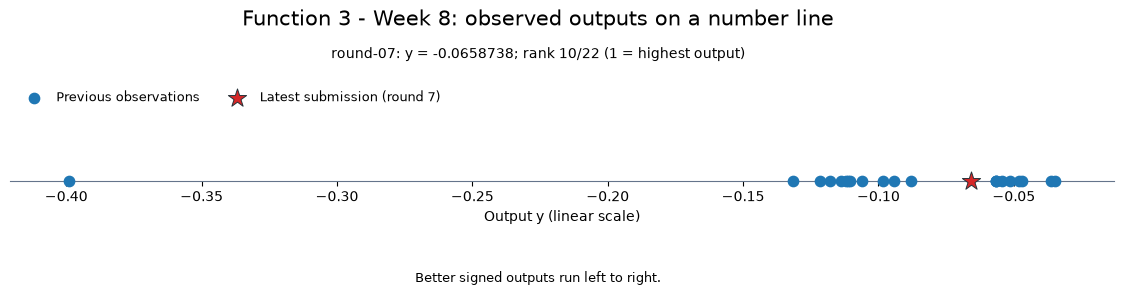

In [4]:
# Original output units and ranks, followed by a display-only zoom.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

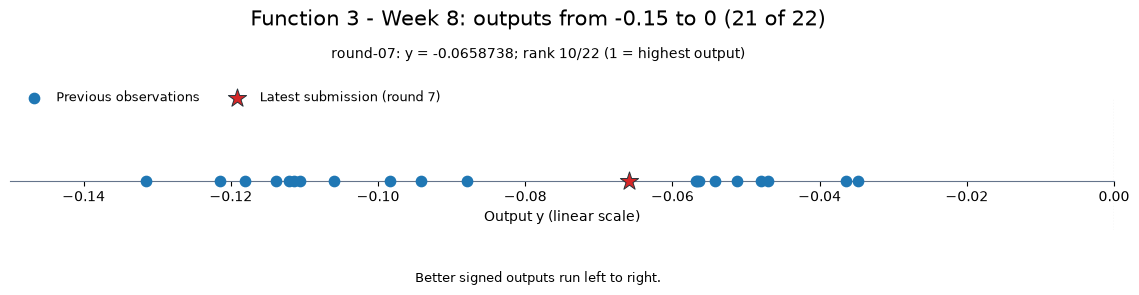

In [5]:
outputs_in_zoom = int(review["outputs"].between(*OUTPUT_ZOOM_LIMITS).sum())
plot_output_number_line(
    review, output_limits=OUTPUT_ZOOM_LIMITS,
    title=f"{TITLE}: outputs from {OUTPUT_ZOOM_LIMITS[0]:g} to {OUTPUT_ZOOM_LIMITS[1]:g} ({outputs_in_zoom} of {len(review['data'])})",
    save_to=FIGURES_DIR / "output-number-line-zoom.png",
)

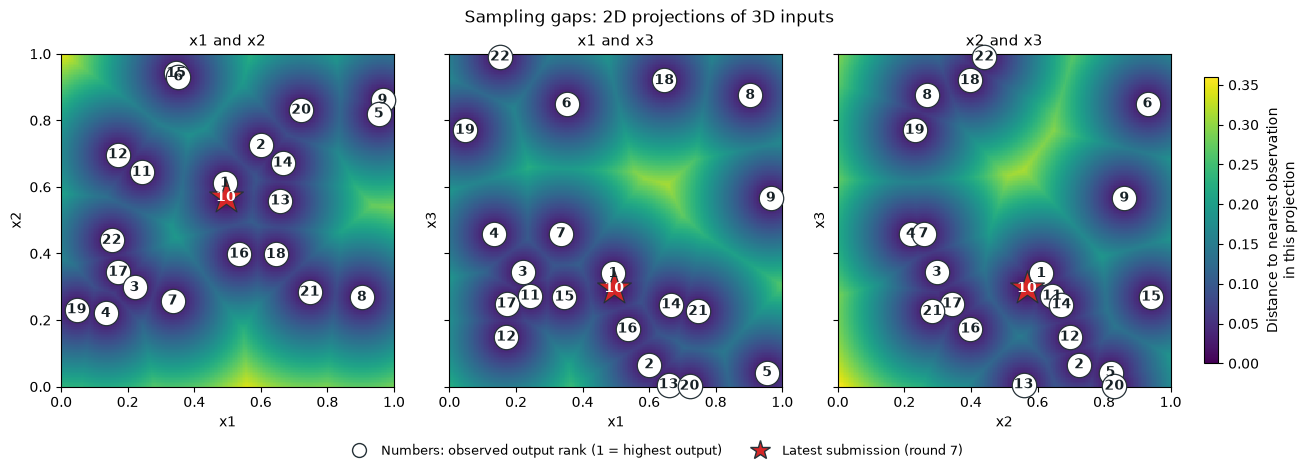

In [6]:
# These distances are measured within each displayed input-pair projection.
plot_sampling_gap_projections(
    review["plot_data"], input_columns=INPUT_COLUMNS, pairs=INPUT_PAIRS,
    highlight=review["latest_mask"], highlight_label=f"Latest submission (round {review['latest_round']})",
    save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [7]:
# All three axes are inputs; measured output is colour, with no fitted surface.
cloud = plot_observed_input_cloud(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed outputs in the three-input space", **CLOUD_SETTINGS,
    save_to=FIGURES_DIR / "observed-input-cloud.html",
)
cloud.show(config={**PLOT_CONFIG, "responsive": CLOUD_SETTINGS["width"] is None})

In [8]:
# Filter this display only; calculations and observed ranks retain every observation.
cloud_zoom = plot_observed_input_cloud(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(), output_limits=OUTPUT_ZOOM_LIMITS,
    title=f"Function {FUNCTION_NUMBER}: outputs from {OUTPUT_ZOOM_LIMITS[0]:g} to {OUTPUT_ZOOM_LIMITS[1]:g} ({outputs_in_zoom} of {len(review['data'])})",
    best_label="Best output in this view", **CLOUD_SETTINGS,
    save_to=FIGURES_DIR / "observed-input-cloud-zoom.html",
)
cloud_zoom.show(config={**PLOT_CONFIG, "responsive": CLOUD_SETTINGS["width"] is None})

The following storyboard records the completed Week 2–4 fixed plan only. The model-led points through round 7 appear in the current coverage view above.

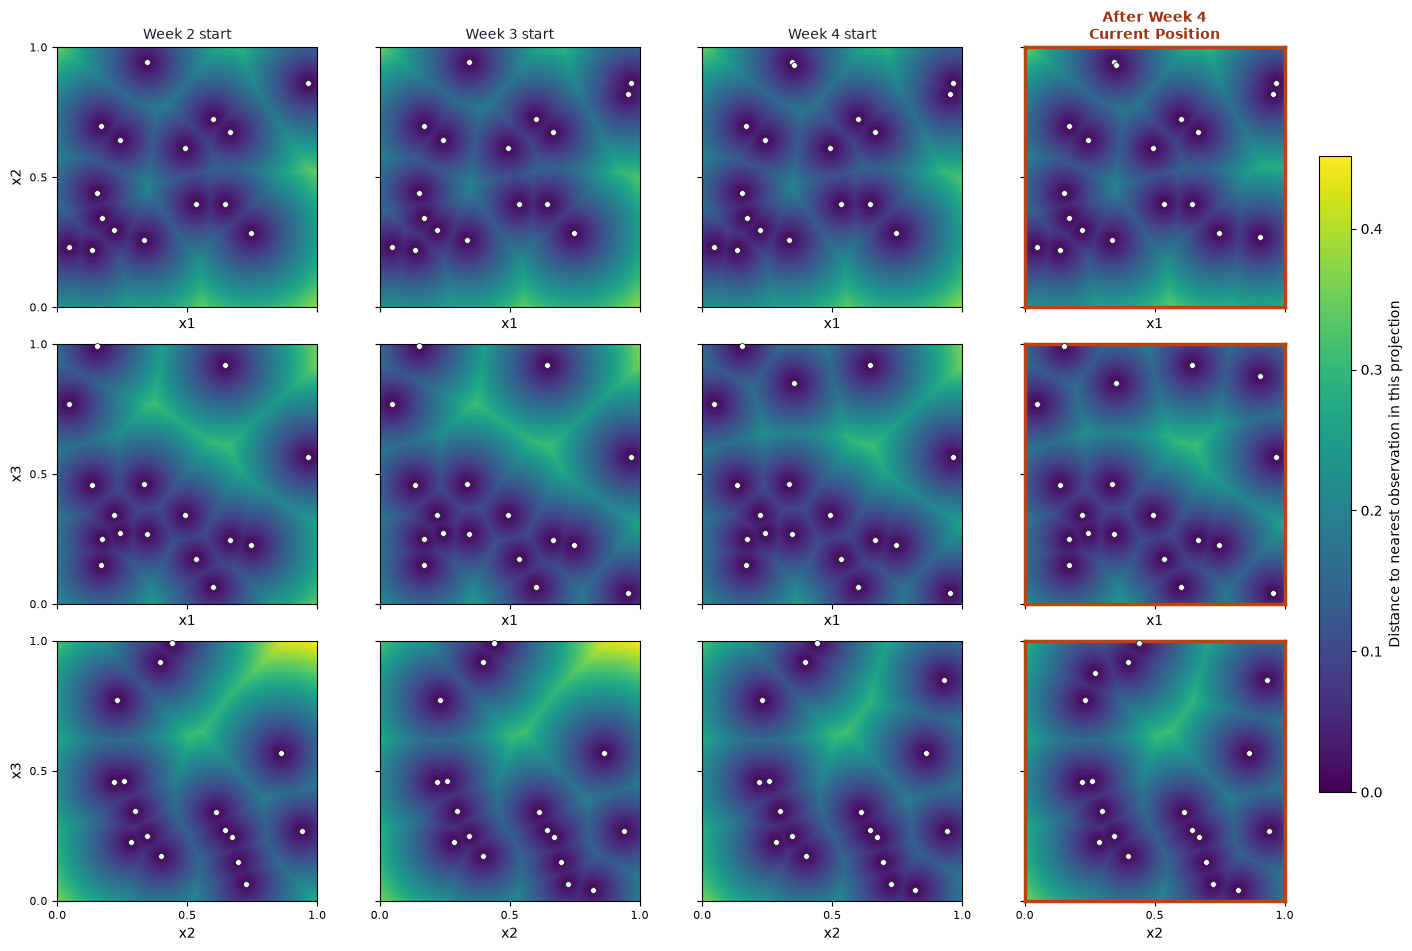

In [9]:
# Recorded official inputs establish the timeline, including their portal precision.
plot_fixed_exploration_projections(
    review["data"].loc[review["data"].source_round < 5], PLANNED_QUERIES, current_week=5,
    first_plan_week=FIRST_PLAN_WEEK, pairs=INPUT_PAIRS, figsize=STORYBOARD_SIZE,
    save_to=FIGURES_DIR / "fixed-exploration-progression-projections.png",
)

In [10]:
# An empty table means the predetermined shortlist has no remaining query.
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK, first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_plan.style.format({column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS}))

,x1,x2,x3,Portal input
Week,,,,


In [11]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

prepared = prepare_weekly_observation_review(review)


### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [12]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=6, na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,-0.034835,Not applicable
Round 1,-0.056431,-0.034835,-0.021596
Round 2,-0.051282,-0.034835,-0.016447
Round 3,-0.054209,-0.034835,-0.019373
Round 4,-0.056642,-0.034835,-0.021807
Round 5,-0.098369,-0.034835,-0.063534
Round 6,-0.121417,-0.034835,-0.086581
Round 7,-0.065874,-0.034835,-0.031039


### Saved Week 7 forecasts at the submitted input

Read the preserved final selection record without refitting. GP latent SD and neural seed SD describe different quantities. Function 1 uses signed-log prediction units; its raw output is also retained. UCB is a selection score.

In [13]:
# Compare only forecasts recorded before the round 7 observation existed.
stage_dir = shared_dir.parent.parent
selection_path = stage_dir / "submissions/Week_07/proposals.json"
if hashlib.sha256(selection_path.read_bytes()).hexdigest() != "23cdcf011d52c2684166b6f1a0aff2bf18d9d542383053c452e0707a3cfb5676":
    raise ValueError("The historical Week 7 selection record has changed.")
selection = next(row for row in json.loads(selection_path.read_text(encoding="utf-8"))["candidates"]
                 if row["function"] == FUNCTION_NUMBER)
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
if not np.array_equal(actual_point, np.asarray(selection["point"], dtype=float)):
    raise ValueError("Saved forecast coordinates do not match the returned query.")
actual_output = float(prepared["latest"][OUTPUT_COLUMN])
actual_target = float(signed_log(actual_output, scale=1e-200)) if FUNCTION_NUMBER == 1 else actual_output
historical_forecast = dict(selection["predictions"])
historical_forecast.update(
    source=selection_path.relative_to(stage_dir).as_posix(), source_sha256="23cdcf011d52c2684166b6f1a0aff2bf18d9d542383053c452e0707a3cfb5676",
    data_scope=selection["data_scope"], selection_policy=selection["selection_policy"],
    prediction_units=selection["prediction_units"], actual_output=actual_output,
    actual_in_prediction_units=actual_target,
    actual_minus_gp_mean=actual_target - historical_forecast["gp_mean"],
    actual_minus_neural_mean=actual_target - historical_forecast["neural_mean"],
)
display(pd.Series(historical_forecast))


point                                                  [0.495233, 0.568579, 0.295191]
portal_input                                               0.495233-0.568579-0.295191
gp_mean                                                                     -0.032887
gp_latent_sd                                                                 0.030731
gp_ucb_1_96                                                                  0.027345
neural_mean                                                                 -0.054904
neural_seed_sd                                                               0.006314
neural_seed_predictions             [-0.04789150304703071, -0.056682697325290334, ...
inside_selected_gp_training_hull                                                 True
nearest_known_input_distance                                                 0.062297
source                                             submissions/Week_07/proposals.json
source_sha256                       23cdcf011d52c26841

### What the return adds

The returned score fell short of the previous best of -0.0348353133501.

In [14]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
(ANALYSIS_DIR / "observation-review.json").write_text(
    json.dumps(observation_summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(observation_summary, indent=2))


{
  "function": 3,
  "week": 8,
  "observations": 22,
  "latest_id": "round-07",
  "latest_output": -0.0658738372473142,
  "latest_rank": 10,
  "rank_definition": "1 = highest output",
  "best_id": "initial-004",
  "best_observed_output": -0.034835313350078584,
  "positive_outputs": 0,
  "negative_outputs": 22,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -0.0564311593911001,
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": -0.021595846041021514
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -0.051282396335886896,
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": -0.016447082985808312
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      

### Course lifecycle for this review

1. **Define the goal and scope** — review round 7 for the project owner and prepare evidence for the Week 8 decision; success means a reconciled return and an accurate descriptive review.
2. **Gather the data** — use the retained 12 November results email, original cumulative attachments and independent official CSV snapshot.
3. **Explore the data** — inspect measured ranks, progress and coverage or full input profiles.
4. **Clean and preprocess the data** — validate dimensions, bounds, finite values and round counts; preserve all rows and full float64 precision.
5. **Select and engineer features** — retain the existing ordered input coordinates; no engineered features are required.
6. **Define the machine-learning task** — continuous black-box maximisation remains the task; this notebook provides descriptive evidence.
7. **Partition the data** — not applicable: no new model is fitted or validated in this observation review.
8. **Select and train candidate methods** — not applicable: any Week 8 model comparison is separate work.
9. **Evaluate and interpret the results** — compare the measured return with earlier outputs, the prior incumbent and the saved forecast where one informed selection.
10. **Deploy and iterate** — no deployment applies; carry this evidence into the next query review. Six query opportunities remain, including Week 8; this notebook submits no query.
